# SISPS-BATT-INT-CAL Impedance

Calibration of SISPS Battery Interposer for Lead Acid Battery Freezing Extent Measurement.

## Setup

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

import matplotlib
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter

from numpy.polynomial import Polynomial

import importlib

from typing import List

In [71]:
importlib.reload(matplotlib)

plt.rcParams.update(
    {
        "figure.dpi": 600,
    }
)

## Data Import

In [72]:
SERIAL_DATA_PATH = "../Data/Serial"
VBATT_DATA_PATH = "../Data/VBATT"

REFERENCE_SATURATION_DATA = "../Data/CrouchReitz.csv"

## Reference Data

In [73]:
def load_reference_saturation_data(path: str) -> pd.DataFrame:
    """
    Load the reference saturation data from a CSV file.

    Args:
            path (str): The path to the CSV file.

    Returns:
            pd.DataFrame: The loaded reference saturation data.
    """
    return pd.read_csv(path)


saturation_data = load_reference_saturation_data(REFERENCE_SATURATION_DATA)

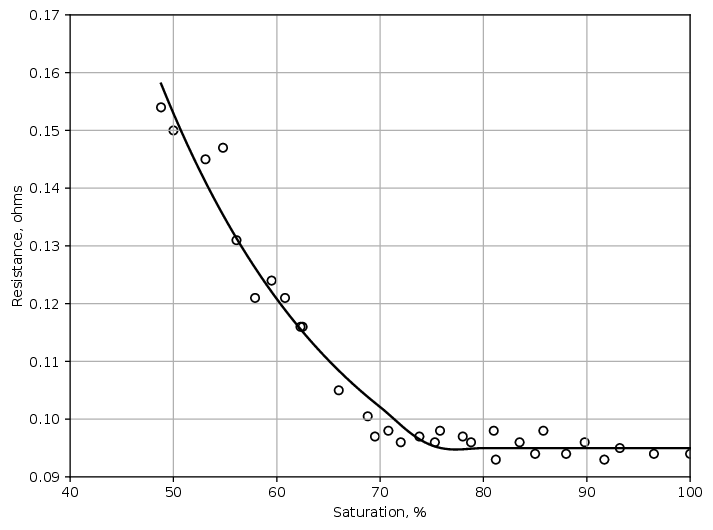

In [74]:
def plot_saturation_data(saturation_data: pd.DataFrame) -> Figure:
    from scipy.optimize import curve_fit

    x = saturation_data["Saturation"].to_numpy(float)
    y = saturation_data["Cell Resistance"].to_numpy(float)
    x0, threshold = x.min(), 80.0
    curve = lambda x, amplitude, rate, asymptote: asymptote + amplitude * np.exp(
        -rate * (x - x0)
    )
    fit = x < threshold
    parameters, _ = curve_fit(
        curve,
        x[fit],
        y[fit],
        p0=(0.08, 0.1, 0.09),
        bounds=([0.0, 0.0, 0.0], [np.inf, np.inf, y[fit].min()]),
    )
    constant = y[~fit].mean()
    transition = 70.0

    def trend(x):
        weight = np.clip((x - transition) / (threshold - transition), 0.0, 1.0)
        weight = weight * weight * (3.0 - 2.0 * weight)
        return (1.0 - weight) * curve(x, *parameters) + weight * constant

    x_fit = np.linspace(x0, 100.0, 400)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(x, y, marker="o", facecolors="none", edgecolors="black")
    ax.plot(x_fit, trend(x_fit), color="black")
    ax.set(
        xlabel="Saturation, %",
        ylabel="Resistance, ohms",
        xlim=(40, 100),
        ylim=(0.09, 0.17),
    )
    ax.grid()
    return fig


plot_saturation_data(saturation_data)

## VBAT Data



In [75]:
def load_vbatt_data(file_path):
    file = os.listdir(file_path)[0]
    df = pd.read_csv(
        os.path.join(file_path, file),
        index_col=0,
    )
    return df


vbatt_df = load_vbatt_data(VBATT_DATA_PATH)

## Serial Data

In [76]:
def load_serial_data(file_path: str) -> pd.DataFrame:
    """
    Load serial data from a Text file and return it as a DataFrame.
    """
    HEADER_LINES = 23

    result = {}
    TEST = os.path.basename(file_path).split(" ")[0]
    BATTERY = os.path.basename(file_path).split(" ")[1]

    print(f"Loading serial data from: {file_path} for test: {TEST}")
    with open(file_path, "r") as file:
        content = file.read()

        lines = content.splitlines()
        header = "\n".join(lines[:HEADER_LINES])
        data = "\n".join(lines[HEADER_LINES:])

    result["test"] = TEST
    result["battery"] = BATTERY
    result["header"] = header

    def parse_data(data: str) -> pd.DataFrame:
        VARIABLES = ["Temp+", "Temp-", "Delta T", "Vrms", "VrmsNull", "Vbatt"]
        dataframe = pd.DataFrame(columns=VARIABLES)

        line_number = 0
        for line in data.splitlines():
            for var in VARIABLES:
                data_point = line.split(f"{var}:")[1].split()[0]
                dataframe.at[line_number, var] = float(data_point)

            line_number += 1

        return dataframe

    result = parse_data(data)
    result.attrs = {"test": TEST, "battery": BATTERY, "header": header}

    return result


dataframes = []

for file_name in os.listdir(SERIAL_DATA_PATH):
    if file_name.endswith(".txt"):
        file_path = os.path.join(SERIAL_DATA_PATH, file_name)
        df = load_serial_data(file_path)
        dataframes.append(df)

Loading serial data from: ../Data/Serial/T07 C07 Serial Output.txt for test: T07
Loading serial data from: ../Data/Serial/T22 C08 Serial Output.txt for test: T22
Loading serial data from: ../Data/Serial/T01 C01 Serial Output.txt for test: T01
Loading serial data from: ../Data/Serial/T21 C07 Serial Output.txt for test: T21
Loading serial data from: ../Data/Serial/T15 C01 Serial Output.txt for test: T15
Loading serial data from: ../Data/Serial/T26 C12 Serial Output.txt for test: T26
Loading serial data from: ../Data/Serial/T10 C10 Serial Output.txt for test: T10
Loading serial data from: ../Data/Serial/T19 C05 Serial Output.txt for test: T19
Loading serial data from: ../Data/Serial/T12 C12 Serial Output.txt for test: T12
Loading serial data from: ../Data/Serial/T14 C14 Serial Output.txt for test: T14
Loading serial data from: ../Data/Serial/T17 C03 Serial Output.txt for test: T17
Loading serial data from: ../Data/Serial/T24 C10 Serial Output.txt for test: T24
Loading serial data from: ..

### Data Preprocessing

In [77]:
dataframes.sort(key=lambda df: df.attrs["test"])

for df in dataframes:
    df["Vrms"] = df["Vrms"] / 1000
    df["VrmsNull"] = df["VrmsNull"] / 1000
    df["Delta T"] = df["Delta T"] / 1000

## Impedance

In [78]:
import re


def get_vrms(vrms_list: list) -> float:
    return pd.Series(vrms_list).tail(3).mean()


def get_vrms_std(vrms_list: list) -> float:
    return pd.Series(vrms_list).tail(3).std()


def get_irms(header: str) -> float:
    match = re.search(r"EIS Current: ([\d.]+) A", header)
    if not match:
        raise ValueError(f"EIS Current not found in header:\n{header}")
    amplitude = float(match.group(1))
    irms = amplitude / np.sqrt(2)  # Irms for Approximate Square Wave
    return irms


def impedance(vrms: float, vrms_null: float, current: float) -> float:
    return (vrms - vrms_null) / current


impedances = {}

for df in dataframes:
    test = df.attrs["test"]
    battery = df.attrs["battery"]
    vrms = get_vrms(df["Vrms"])
    vrms_std = get_vrms_std(df["Vrms"])
    vrms_null = get_vrms(df["VrmsNull"])
    irms = get_irms(df.attrs["header"])

    impedances[test] = impedance(vrms, vrms_null, irms)
    impedances_std = vrms_std / irms

    print(
        f"Test: {test}, Battery: {battery}, Vrms: {1000*vrms:.3f} mV, VrmsNull: {1000*vrms_null:.3f} mV, Irms: {1000*irms:.3f} mA, Impedance: {impedances[test]:.6f} ± {impedances_std:.6f} Ω, Error: ±{100*impedances_std/impedances[test]:.1f} %"
    )

Test: T01, Battery: C01, Vrms: 34.391 mV, VrmsNull: 2.164 mV, Irms: 106.066 mA, Impedance: 0.303839 ± 0.000480 Ω, Error: ±0.2 %
Test: T02, Battery: C02, Vrms: 31.371 mV, VrmsNull: 2.179 mV, Irms: 106.066 mA, Impedance: 0.275225 ± 0.002343 Ω, Error: ±0.9 %
Test: T03, Battery: C03, Vrms: 34.438 mV, VrmsNull: 2.163 mV, Irms: 106.066 mA, Impedance: 0.304288 ± 0.001107 Ω, Error: ±0.4 %
Test: T04, Battery: C04, Vrms: 29.949 mV, VrmsNull: 2.174 mV, Irms: 106.066 mA, Impedance: 0.261865 ± 0.000304 Ω, Error: ±0.1 %
Test: T05, Battery: C05, Vrms: 30.191 mV, VrmsNull: 2.188 mV, Irms: 106.066 mA, Impedance: 0.264021 ± 0.000481 Ω, Error: ±0.2 %
Test: T06, Battery: C06, Vrms: 25.251 mV, VrmsNull: 2.164 mV, Irms: 106.066 mA, Impedance: 0.217669 ± 0.000764 Ω, Error: ±0.4 %
Test: T07, Battery: C07, Vrms: 33.803 mV, VrmsNull: 2.167 mV, Irms: 106.066 mA, Impedance: 0.298264 ± 0.001182 Ω, Error: ±0.4 %
Test: T08, Battery: C08, Vrms: 25.107 mV, VrmsNull: 2.188 mV, Irms: 106.066 mA, Impedance: 0.216082 ± 0.

In [79]:
def plot_impedances(impedances: dict):
    tests = list(impedances.keys())
    impedance_values = list(impedances.values())

    plt.figure(figsize=(10, 6))
    plt.bar(tests, impedance_values, color="blue")
    plt.xlabel("Battery")
    plt.ylabel("Impedance (Ohms)")
    plt.title("Battery Impedance Comparison")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_impedances(impedances)

/var/folders/3f/ct0r54cd0497vnq7h8jk96q40000gp/T/ipykernel_47753/3618822764.py:13: UserWarning: FigureCanvasPgf is non-interactive, and thus cannot be shown
  plt.show()


## Conditions

In [80]:
def electrolyte_mass_fraction(emf_ht: float):
    """
    Calculate the acid mass fraction based on the EMF at room temperature.
    """
    # From UCT002 electrolyte measurements as Published in Observations of Freezing Lead Acid Batteries using EIS, Stanton 2025
    return (emf_ht - 1.824) / 0.784


def plot_acid_concentration_per_test(vbatt_df: pd.DataFrame):
    tests = vbatt_df.index.tolist()
    acid_concentrations = [
        electrolyte_mass_fraction(vbatt_df.loc[test, "VBATT HT"] / 6) for test in tests
    ]

    plt.figure(figsize=(10, 6))
    plt.scatter(tests, acid_concentrations, color="green")
    plt.xlabel("Battery")
    plt.ylabel("Acid Mass Fraction")
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    plt.ylim(bottom=0)
    plt.title("Acid Mass Fraction per Test")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_acid_concentration_per_test(vbatt_df)

/var/folders/3f/ct0r54cd0497vnq7h8jk96q40000gp/T/ipykernel_47753/1065368454.py:25: UserWarning: FigureCanvasPgf is non-interactive, and thus cannot be shown
  plt.show()


In [81]:
def plot_vbatt_change(vbatt_df: pd.DataFrame):
    for test in vbatt_df.index:
        vbatt_ht = vbatt_df.loc[test, "VBATT HT"]
        vbatt_lt = vbatt_df.loc[test, "VBATT LT"]

        plt.scatter(
            vbatt_ht,  # type: ignore
            vbatt_lt,  # type: ignore
            label=test,
            color="green" if int(test[1:]) < 15 else "blue",
        )

    plt.plot([11.2, 12.8], [11.2, 12.8], color="gray", linestyle="--")

    plt.grid(axis="both")
    plt.xlim(11.2, 12.8)
    plt.ylim(11.2, 12.8)


plot_vbatt_change(vbatt_df)

## Freezing Extent

In [82]:
def freezing_extent(vbatt_ht: float, vbatt_lt: float) -> float:
    if vbatt_ht > vbatt_lt:
        return 0.0  # Negative Thermal Gradient, No Freezing

    OFFSET = 1.824  # Linear zero offset of Cell Voltage to Electrolyte Concentration
    f = 1 - (vbatt_ht - OFFSET) / (vbatt_lt - OFFSET)
    return f


freezing_extents = {}

for battery in vbatt_df.index:
    vbatt_ht = vbatt_df.loc[battery, "VBATT HT"] / 6  # type: ignore
    vbatt_lt = vbatt_df.loc[battery, "VBATT LT"] / 6  # type: ignore

    f = freezing_extent(vbatt_ht=vbatt_ht, vbatt_lt=vbatt_lt)  # type: ignore

    freezing_extents[battery] = f

freezing_extents_df = pd.DataFrame.from_dict(
    freezing_extents, orient="index", columns=["Freezing Extent"]
)
freezing_extents_df["VBATT HT"] = vbatt_df["VBATT HT"] / 6
freezing_extents_df["VBATT LT"] = vbatt_df["VBATT LT"] / 6
freezing_extents_df.index.name = "Test"

print(freezing_extents_df)

      Freezing Extent  VBATT HT  VBATT LT
Test                                     
T01          0.000000  2.126283  2.120283
T02          0.000000  2.113650  2.101450
T03          0.000000  2.099083  2.095667
T04          0.000000  2.084767  2.079667
T05          0.000000  2.068917  2.063000
T06          0.000000  2.054883  2.050500
T07          0.076426  2.035883  2.053417
T08          0.107310  2.021433  2.045167
T09          0.159634  2.007550  2.042417
T10          0.222984  1.991628  2.039733
T11          0.292763  1.974983  2.037483
T12          0.365079  1.958212  2.035383
T13          0.432838  1.942367  2.032700
T14          0.512001  1.924845  2.030650
T15          0.103107  2.013050  2.034783
T16          0.165741  1.998193  2.032800
T17          0.166691  1.998412  2.033300
T18          0.228452  1.983993  2.031367
T19          0.441518  1.936925  2.026200
T20          0.389999  1.948430  2.027983
T21          0.482626  1.930458  2.029767
T22          0.539600  1.917300  2

In [83]:
def plot_freezing_extents(freezing_extents: dict):
    batteries = list(freezing_extents.keys())
    freezing_values = list(freezing_extents.values())

    plt.figure(figsize=(10, 6))
    plt.bar(batteries, freezing_values)
    plt.xlabel("Battery")
    plt.ylabel("Freezing Extent")
    plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{100*y:.0f}%"))
    plt.title("Battery Freezing Extent Comparison")
    plt.xticks(rotation=45)
    plt.grid(axis="y")
    plt.tight_layout()
    plt.show()


plot_freezing_extents(freezing_extents)

/var/folders/3f/ct0r54cd0497vnq7h8jk96q40000gp/T/ipykernel_47753/413133443.py:14: UserWarning: FigureCanvasPgf is non-interactive, and thus cannot be shown
  plt.show()


In [84]:
def plot_impedance_vs_freezing(
    impedances: dict,
    freezing_extents: dict,
    include_non_freezing: bool = False,
    filter_outliers: List[str] | None = None,
    annotate: bool = False,
) -> Figure:
    fig, ax = plt.subplots(
        figsize=(8, 6),
    )

    for test in impedances.keys():
        impedance_value = impedances[test]
        freezing_value = freezing_extents.get(test, 0.0)

        if filter_outliers and test in filter_outliers:
            continue

        if freezing_value > 0.0 or include_non_freezing:
            ax.scatter(
                freezing_value,
                impedance_value,
                label=test,
                color="black" if not annotate else None,
                s=20,
            )
            if annotate:
                ax.annotate(
                    test,
                    (freezing_value, impedance_value),
                    textcoords="offset points",
                    xytext=(5, 5),
                    ha="center",
                )

    plt.ylabel("Impedance")
    plt.xlabel("Freezing Extent")
    plt.title("Battery Impedance vs Freezing Extent")
    plt.grid()

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{100*x:.0f}%"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: rf"{y:.1f}\textohm"))

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

    IMPEDANCE_THRESHOLD = 0.5
    threshold_items = [
        (freezing_extents[test], impedance)
        for test, impedance in impedances.items()
        if impedance > IMPEDANCE_THRESHOLD
        and ((filter_outliers is None) or (test not in filter_outliers))
    ]

    def get_linear_correlation(items):
        p = Polynomial.fit([x for x, _ in items], [y for _, y in items], deg=1)
        monomial = p.convert()
        a, b = monomial.coef[1], monomial.coef[0]
        r2 = np.corrcoef([x for x, _ in items], [y for _, y in items])[0, 1] ** 2

        return p, a, b, r2

    p, a, b, r2 = get_linear_correlation(threshold_items)
    x_lims = [threshold_items[0][0], threshold_items[-1][0]]
    x_lims = x_lims + np.array([-0.05, 0.05])

    ax.plot(
        x_lims,
        p(x_lims),
        linestyle="--",
        color="grey",
    )
    ax.text(
        0.05,
        0.80,
        rf"$F > 37.5\%: Z = ({a:.2f} \cdot F {'+' if b >= 0 else '-'} {abs(b):.2f})\,\Omega \quad R^2 = {r2:.2f}$",
        transform=ax.transAxes,
        fontsize=12,
        verticalalignment="top",
        backgroundcolor="white",
    )

    below_threshold_items = [
        (freezing_extents[test], impedance)
        for test, impedance in impedances.items()
        if impedance <= IMPEDANCE_THRESHOLD
        and ((filter_outliers is None) or (test not in filter_outliers))
    ]
    below_threshold_mean = np.mean([y for _, y in below_threshold_items])
    below_threshold_std = np.std([y for _, y in below_threshold_items])
    ax.hlines(
        y=below_threshold_mean,
        xmin=0,
        xmax=below_threshold_items[-1][0] + 0.05,
        linestyle="--",
        color="grey",
    )
    ax.text(
        0.05,
        0.75,
        rf"$F < 37.5\%: Z_0 = {below_threshold_mean:.2f} \pm {below_threshold_std:.2f}\,\Omega$",
        transform=ax.transAxes,
        fontsize=12,
        verticalalignment="top",
        backgroundcolor="white",
    )

    return fig


OUTLIERS = ["T26", "T27", "T28"]
# OUTLIERS = ["T26"]

_ = plot_impedance_vs_freezing(
    impedances,
    freezing_extents,
    include_non_freezing=True,
    filter_outliers=OUTLIERS,
    annotate=True,
)

In [85]:
_ = plot_impedance_vs_freezing(
    impedances,
    freezing_extents,
    include_non_freezing=True,
    filter_outliers=OUTLIERS + [f"T{i}" for i in range(15, 29)],
    annotate=True,
)

In [86]:
from matplotlib.patches import Patch


def plot_impedence_vs_concentration(
    impedances: dict,
    concentrations: dict,
    freezing_extents: dict,
    filter_outliers: List[str] | None = None,
) -> Figure:
    fig, ax = plt.subplots(
        figsize=(8, 6),
    )

    for test in impedances.keys():
        if filter_outliers and test in filter_outliers:
            continue

        impedance_value = impedances[test]
        concentration_value = concentrations.get(test, 0.0)

        ax.scatter(
            concentration_value,
            impedance_value,
            label=test,
            color="black" if freezing_extents.get(test, 0.0) == 0.0 else "red",
        )

    THRESHOLDS = [(-10, 0.17), (-15, 0.21), (-20, 0.24), (-25, 0.26)]

    for temp, conc in THRESHOLDS:
        plt.vlines(
            [conc],
            0,
            2,
            linestyle="--",
        )
        ax.annotate(
            f"{temp}C",
            (conc, ax.get_ylim()[1]),
            textcoords="offset points",
            xytext=(0, -10),
            ha="center",
            va="top",
            size=8,
        )

    plt.ylabel("Impedance")
    plt.xlabel("Acid Mass Fraction")
    plt.title("Battery Impedance vs Acid Mass Fraction")
    plt.grid()

    legend_handles = []
    if any(freezing_extents.get(t, 0.0) > 0.0 for t in impedances.keys()):
        legend_handles.append(Patch(color="red", label="Frozen"))
    if any(freezing_extents.get(t, 0.0) == 0.0 for t in impedances.keys()):
        legend_handles.append(Patch(color="black", label="Unfrozen"))
    if legend_handles:
        ax.legend(handles=legend_handles)

    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
    # ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.2f}Ω"))

    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    # ax.set_xscale("log")
    # ax.set_yscale("log")

    return fig


concentrations = {
    test: electrolyte_mass_fraction(vbatt_df.loc[test, "VBATT HT"] / 6)  # type: ignore
    for test in impedances.keys()
}

_ = plot_impedence_vs_concentration(
    impedances,
    concentrations,
    freezing_extents,
    filter_outliers=OUTLIERS,
)

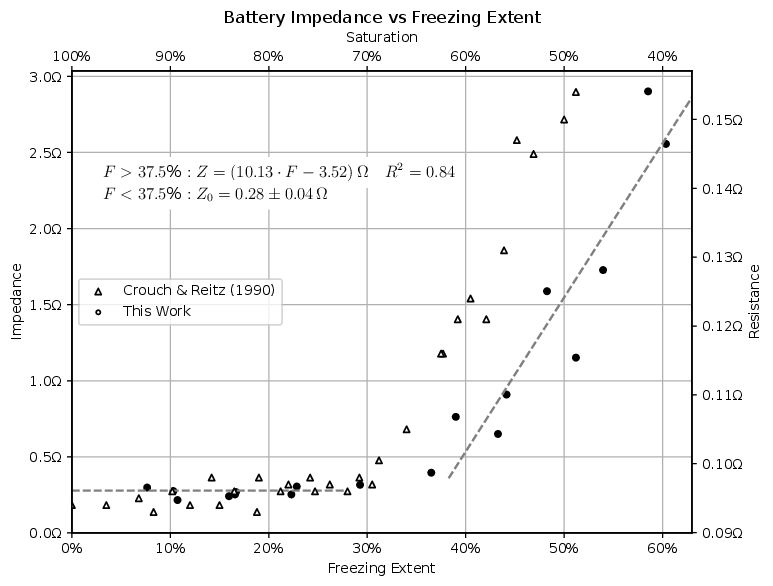

In [87]:
def add_saturation_to_impedance_plot(
    fig: Figure,
    saturation_data: pd.DataFrame,
    nominal_saturation: float = 1.0,
) -> Figure:
    ax1 = fig.gca()
    ax2 = ax1.twinx()

    ax2.scatter(
        (1 - saturation_data["Saturation"] / 100) - (1 - nominal_saturation),
        saturation_data["Cell Resistance"],
        s=20,
        marker="^",
        color="white",
        edgecolor="black",
        label=r"Crouch \& Reitz (1990)",
    )
    ax2.set_ylabel("Resistance")
    ax2.yaxis.set_major_formatter(FuncFormatter(lambda y, _: rf"{y:.2f}\textohm"))
    # ax2.set_ylim(ax1.get_ylim())

    # Add second x-axis for saturation
    ax3 = ax1.twiny()
    ax3.set_xticks(ax1.get_xticks())
    ax3.set_xlim(ax1.get_xlim())
    ax3.set_xticklabels([rf"{nominal_saturation - x:.0%}" for x in ax1.get_xticks()])
    ax3.set_xlabel("Saturation")

    # Dummy scatter for legend
    ax2.scatter(
        [],
        [],
        marker=".",
        color="white",
        edgecolor="black",
        label="This Work",
    )

    ax2.legend(loc="center left")

    return fig


impedance_vs_freezing_fig = plot_impedance_vs_freezing(
    impedances=impedances,
    freezing_extents=freezing_extents,
    filter_outliers=OUTLIERS,
    annotate=False,
)

add_saturation_to_impedance_plot(
    fig=impedance_vs_freezing_fig,
    saturation_data=saturation_data,
    nominal_saturation=1.0,
)

## Exports

In [88]:
import matplotlib

matplotlib.use("pgf")

plt.rcParams.update(matplotlib.rcParamsDefault)
plt.rcParams.update(
    {
        "pgf.texsystem": "pdflatex",
        "text.usetex": True,
        "pgf.rcfonts": False,
        # "axes.prop_cycle": cycler(color=colorBlindColors),
    }
)

PGF_OUTPUT_PATH = "../Plots/Latex"
os.makedirs(PGF_OUTPUT_PATH, exist_ok=True)

In [89]:
freezing_impedance_fig = plot_impedance_vs_freezing(
    impedances,
    freezing_extents,
    filter_outliers=OUTLIERS,
    annotate=False,
)

freezing_impedance_fig.axes[0].set_title("")

freezing_impedance_fig.axes[0].yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: rf"{y:.1f}\textohm")
)

freezing_impedance_fig.savefig(
    os.path.join(PGF_OUTPUT_PATH, "impedance_vs_freezing.pgf")
)